# Grid Pulse EV — PUCSL 2024 source-level energy audit

**Stage 1.8, Task A.** Compare the **original daily Energy (MWh) values** in the January 2024 PUCSL workbook with the **15-minute integrated source energy** already produced by the project's quality-aware preprocessor.

This notebook is **diagnostic**. It does not modify raw data, preprocessing scripts, or the approved research model. It writes only outputs under `results/pucsl_source_audit/`.

**Caveats:** category coverage and measurement boundaries may differ; no difference is evidence of measured curtailment. The time labels are currently interpreted *provisionally* as interval-ending labels.

## 1. Locate your project and original January workbook

Run each cell in order. If more than one January workbook is found, specify the correct file in `RAW_WORKBOOK_OVERRIDE`.

In [8]:
from pathlib import Path
from zipfile import ZipFile
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name.lower() == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "scripts" / "preprocess_pucsl_dispatch.py").exists():
    raise FileNotFoundError(f"Open this notebook from the Grid Pulse EV repository (current: {ROOT})")
sys.path.insert(0, str(ROOT / "scripts"))
import preprocess_pucsl_dispatch as pre

RAW_WORKBOOK_OVERRIDE = None  # e.g. '15-Minutes-Report-31st-Jan-2024(2).xlsx'
RAW_DIR = ROOT / "data/raw/grid/pucsl"
CANDIDATES = sorted(p for p in RAW_DIR.glob("*.xlsx") if "jan" in p.name.lower() and "2024" in p.name.lower())
print("January 2024 workbook candidates:", [p.name for p in CANDIDATES])
if RAW_WORKBOOK_OVERRIDE is not None:
    WORKBOOK = RAW_DIR / RAW_WORKBOOK_OVERRIDE
elif len(CANDIDATES) == 1:
    WORKBOOK = CANDIDATES[0]
else:
    raise ValueError("Expected one January 2024 workbook. Set RAW_WORKBOOK_OVERRIDE to the correct filename.")
if not WORKBOOK.exists():
    raise FileNotFoundError(WORKBOOK)
RECON_PATH = ROOT / "data/processed/grid/pucsl_2024_01_reconciliation.csv"
if not RECON_PATH.exists():
    raise FileNotFoundError(f"Processed January reconciliation missing: {RECON_PATH}")
print("Selected workbook:", WORKBOOK.name)
print("Processed reconciliation:", RECON_PATH.name)

January 2024 workbook candidates: ['15-Minutes-Report-31st-Jan-2024.xlsx']
Selected workbook: 15-Minutes-Report-31st-Jan-2024.xlsx
Processed reconciliation: pucsl_2024_01_reconciliation.csv


## 2. Read the source’s original daily energy cells

The source has eight generation categories in the bottom summary table. Column `CT` is labeled `Energy/(MWh)`. We reuse the project preprocessor’s Excel XML reader, avoiding any changed parser assumptions.

In [9]:
SOURCE_TO_PROCESSED = {
    "Coal": "coal_integrated_mwh",
    "Oil- CEB owned": "oil_ceb_integrated_mwh",
    "Oil-IPP owned": "oil_ipp_integrated_mwh",
    "Major Hydro": "major_hydro_integrated_mwh",
    "Wind": "wind_integrated_mwh",
    "Solar": "solar_integrated_mwh",
    "Biomass": "biomass_integrated_mwh",
    "Mini Hydro": "mini_hydro_integrated_mwh",
}

def extract_source_daily_energy(workbook):
    out = []
    with ZipFile(workbook) as z:
        shared = pre._read_shared_strings(z)
        sheets = [(name, ref) for name, ref in pre._sheet_refs(z) if pre._is_date_sheet(name)]
        date_order = pre.detect_sheet_date_order([name for name, _ in sheets], 2024, 1, allow_partial=True)
        for name, ref in sheets:
            cells = pre._read_cells(z, ref, shared)
            labels = {}
            for address, value in cells.items():
                if address.startswith("A") and address[1:].isdigit() and int(address[1:]) >= 40:
                    normalized = pre._normalized(value)
                    if normalized in {pre._normalized(s) for s in SOURCE_TO_PROCESSED}:
                        if normalized in labels:
                            raise ValueError(f"Duplicated source label on {name}: {value}")
                        labels[normalized] = int(address[1:])
            record = {
                "operating_date": pre.sheet_operating_date(name, 2024, 1, date_order).isoformat(),
                "source_sheet": name,
            }
            for label in SOURCE_TO_PROCESSED:
                normalized = pre._normalized(label)
                if normalized not in labels:
                    raise ValueError(f"Source '{label}' absent on worksheet {name}")
                cell = f"CT{labels[normalized]}"
                record[f"reported_{SOURCE_TO_PROCESSED[label]}"] = pre._numeric(cells.get(cell), f"{name}!{cell}")
            total_rows = [int(addr[1:]) for addr, value in cells.items()
                          if addr.startswith("A") and addr[1:].isdigit()
                          and pre._normalized(value).startswith("totalmw")]
            if len(total_rows) != 1:
                raise ValueError(f"Expected exactly one TotalMW row on {name}; found {total_rows}")
            record["reported_total_energy_mwh"] = pre._numeric(cells.get(f"CT{total_rows[0]}"), f"{name}!CT{total_rows[0]}")
            out.append(record)
    df = pd.DataFrame(out).sort_values("operating_date").reset_index(drop=True)
    if df.operating_date.duplicated().any():
        raise ValueError("Duplicate operating dates in workbook")
    print(f"Read {len(df)} original daily worksheets; first and last dates: {df.operating_date.iloc[0]}, {df.operating_date.iloc[-1]}")
    return df

original_daily = extract_source_daily_energy(WORKBOOK)
display(original_daily.head(3))

Read 31 original daily worksheets; first and last dates: 2024-01-01, 2024-01-31


,operating_date,source_sheet,reported_coal_integrated_mwh,reported_oil_ceb_integrated_mwh,reported_oil_ipp_integrated_mwh,reported_major_hydro_integrated_mwh,reported_wind_integrated_mwh,reported_solar_integrated_mwh,reported_biomass_integrated_mwh,reported_mini_hydro_integrated_mwh,reported_total_energy_mwh
0,2024-01-01,01.01,5329.0,61.9,222.0,23738.6,1564.4,2079.6,268.2,4207.8,37471.6
1,2024-01-02,01.02,5810.0,519.1,842.1,24974.1,1583.3,2103.6,240.5,4868.6,40941.3
2,2024-01-03,01.03,6140.0,1136.2,2080.1,25419.5,1156.8,2280.4,128.9,4415.4,42757.4


## 3. Match daily reports with integrated 15-minute figures

All computations use MWh. This comparison is strictly **within the PUCSL workbook**; CEB monthly statistics are not mixed into it.

In [10]:
integrated = pd.read_csv(RECON_PATH)
required = {"operating_date", *SOURCE_TO_PROCESSED.values(), "total_dispatch_reported_integrated_mwh"}
missing = required - set(integrated.columns)
if missing:
    raise ValueError(f"Reconciliation CSV missing columns: {sorted(missing)}")
daily = original_daily.merge(integrated, on="operating_date", how="outer", validate="one_to_one", indicator=True,
                             suffixes=("_original", "_processed"))
if not daily["_merge"].eq("both").all():
    raise ValueError("Original worksheets and processed dates do not align; inspect _merge column")

daily["total_gap_mwh"] = daily["reported_total_energy_mwh"] - daily["total_dispatch_reported_integrated_mwh"]
for source, integ in SOURCE_TO_PROCESSED.items():
    daily[f"gap_{integ}"] = daily[f"reported_{integ}"] - daily[integ]
print(f"Aligned {len(daily)} days between original workbook and processed CSV")
show_cols = ["operating_date", "reported_total_energy_mwh", "total_dispatch_reported_integrated_mwh", "total_gap_mwh"]
display(daily[show_cols].head(7))

Aligned 31 days between original workbook and processed CSV


,operating_date,reported_total_energy_mwh,total_dispatch_reported_integrated_mwh,total_gap_mwh
0,2024-01-01,37471.6,34204.75,3266.85
1,2024-01-02,40941.3,37835.25,3106.05
2,2024-01-03,42757.4,39912.75,2844.65
3,2024-01-04,43895.6,40991.75,2903.85
4,2024-01-05,44337.5,41240.25,3097.25
5,2024-01-06,41069.2,37854.50,3214.70
6,2024-01-07,35652.5,32450.50,3202.00


## 4. Monthly breakdown by generation source

**Positive gap** means the original daily reported MWh is higher than the energy obtained by integrating the 96 observations.

In [11]:
summary = []
for source, integ in SOURCE_TO_PROCESSED.items():
    reported = daily[f"reported_{integ}"].sum()
    from_intervals = daily[integ].sum()
    summary.append({"source": source, "reported_daily_gwh": reported / 1000,
                    "integrated_15min_gwh": from_intervals / 1000,
                    "difference_gwh": (reported - from_intervals) / 1000})
source_summary = pd.DataFrame(summary)
source_summary["absolute_difference_gwh"] = source_summary.difference_gwh.abs()
source_summary = source_summary.sort_values("absolute_difference_gwh", ascending=False)
display(source_summary.drop(columns="absolute_difference_gwh").round(3))

total_gap_gwh = daily.total_gap_mwh.sum() / 1000
sum_source_gaps_gwh = source_summary.difference_gwh.sum()
residual_gwh = total_gap_gwh - sum_source_gaps_gwh
print(f"Total gap (daily reported minus integrated): {total_gap_gwh:,.3f} GWh")
print(f"Sum of eight source gaps: {sum_source_gaps_gwh:,.3f} GWh")
print(f"Unattributed arithmetic residual: {residual_gwh:,.3f} GWh")
print("Differences alone do not establish the physical source or reason for the gaps.")

,source,reported_daily_gwh,integrated_15min_gwh,difference_gwh
5,Solar,69.527,14.520,55.007
7,Mini Hydro,127.033,102.695,24.337
6,Biomass,11.041,1.947,9.094
4,Wind,38.440,35.278,3.162
1,Oil- CEB owned,57.485,58.677,-1.192
2,Oil-IPP owned,45.707,46.861,-1.154
3,Major Hydro,623.357,624.012,-0.656
0,Coal,323.886,323.303,0.583


Total gap (daily reported minus integrated): 89.227 GWh
Sum of eight source gaps: 89.183 GWh
Unattributed arithmetic residual: 0.045 GWh
Differences alone do not establish the physical source or reason for the gaps.


## 5. Source-specific gap chart

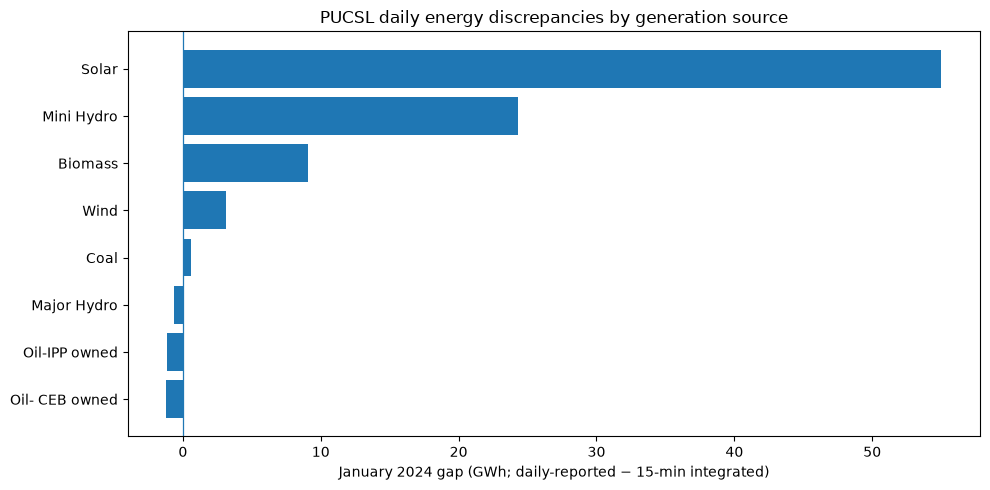

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
s = source_summary.sort_values("difference_gwh")
ax.barh(s["source"], s["difference_gwh"])
ax.axvline(0, linewidth=0.9)
ax.set_xlabel("January 2024 gap (GWh; daily-reported − 15-min integrated)")
ax.set_title("PUCSL daily energy discrepancies by generation source")
plt.tight_layout()
plt.show()

## 6. Check the timestamp convention **without changing it**

The preprocessor already records source time labels as provisional interval **ends** (first `00:15`, last `00:00` on the next day), while storing derived start and end times. We review the stored mapping before the EV hourly model uses it.

In [13]:
DISPATCH_PATH = ROOT / "data/processed/grid/pucsl_2024_01_dispatch_15min.csv"
if DISPATCH_PATH.exists():
    interval_data = pd.read_csv(DISPATCH_PATH)
    expected_time_columns = ["operating_date", "interval_number", "source_time_label", "interval_start_local", "interval_end_local"]
    if set(expected_time_columns).issubset(interval_data.columns):
        first_day = interval_data[interval_data["operating_date"].astype(str) == "2024-01-01"]
        display(pd.concat([first_day.head(2), first_day.tail(2)])[expected_time_columns])
        print("Review: first source label should be 0:15, last 0:00; first mapped start 00:00 and last 23:45 on Jan 1.")
    else:
        print("Processed file has different headers:", interval_data.columns.tolist())
else:
    print("Optional 15-minute January CSV not found; timestamp mapping review skipped")
print("IMPORTANT: interval-ending convention remains provisional pending data-owner confirmation.")

,operating_date,interval_number,source_time_label,interval_start_local,interval_end_local
0,2024-01-01,1,0:15,2024-01-01T00:00:00+05:30,2024-01-01T00:15:00+05:30
1,2024-01-01,2,0:30,2024-01-01T00:15:00+05:30,2024-01-01T00:30:00+05:30
94,2024-01-01,95,23:45,2024-01-01T23:30:00+05:30,2024-01-01T23:45:00+05:30
95,2024-01-01,96,0:00,2024-01-01T23:45:00+05:30,2024-01-02T00:00:00+05:30


Review: first source label should be 0:15, last 0:00; first mapped start 00:00 and last 23:45 on Jan 1.
IMPORTANT: interval-ending convention remains provisional pending data-owner confirmation.


## 7. Save diagnostic outputs (optional)

These are **new** results only. Original XLSX files, processed input CSVs and project scripts are not changed.

In [14]:
OUTDIR = ROOT / "results/pucsl_source_audit"
OUTDIR.mkdir(parents=True, exist_ok=True)
source_summary.drop(columns="absolute_difference_gwh").to_csv(OUTDIR / "pucsl_2024_01_source_gap_summary.csv", index=False)
daily.drop(columns="_merge").to_csv(OUTDIR / "pucsl_2024_01_daily_source_gap.csv", index=False)
print("Saved January source-level comparison tables in:", OUTDIR)
print("Next: independently verify category definitions in CEB/PUCSL documentation; do not alter raw data to force agreement.")

Saved January source-level comparison tables in: C:\Users\isuru\Documents\Projects\grid-pulse-ev-starter\results\pucsl_source_audit
Next: independently verify category definitions in CEB/PUCSL documentation; do not alter raw data to force agreement.
